In [1]:
import os
import requests
import zipfile
import torch
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# downloading the dataset

RECORD_ID = "17552872"

BASE_DIR = Path("/content/apple_detection")
DOWNLOAD_DIR = BASE_DIR / "downloads"
DATA_DIR = BASE_DIR / "dataset"
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

API_URL = f"https://zenodo.org/api/records/{RECORD_ID}"
response = requests.get(API_URL, timeout=30)
response.raise_for_status()
record = response.json()
print("\nDataset:", record["metadata"]["title"])

required_files = ["images.zip", "annotation.zip"]
for filename in required_files:
    file_info = next(
        (
            f for f in record["files"]
            if f["key"] == filename
        ),
        None
    )
    if file_info is None:
        raise FileNotFoundError(
            f"{filename} not found in Zenodo record."
        )
    archive_path = DOWNLOAD_DIR / filename
    if not archive_path.exists():
        print(f"\nDownloading {filename}...")
        download_url = file_info["links"]["self"]
        with requests.get(
            download_url,
            stream=True,
            timeout=60
        ) as r:
            r.raise_for_status()
            with open(archive_path, "wb") as f:
                for chunk in r.iter_content(1024 * 1024):
                    if chunk:
                        f.write(chunk)
    print(
        filename,
        "size:",
        round(archive_path.stat().st_size / (1024**2), 2),
        "MB"
    )

    with zipfile.ZipFile(archive_path, "r") as z:
        z.extractall(DATA_DIR)

print("\nDataset downloaded and extracted!")

all_files = [
    f for f in DATA_DIR.rglob("*")
    if f.is_file()
]

image_files = [
    f for f in all_files
    if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

annotation_files = [
    f for f in all_files
    if f.suffix.lower() == ".txt"
]

print("\nTotal files:", len(all_files))
print("Image files:", len(image_files))
print("Annotation files:", len(annotation_files))


Device: cuda
GPU: Tesla T4

Dataset: An Annotated Image Dataset for Apple Fruit Detection

images.zip size: 220.64 MB

annotation.zip size: 0.29 MB

Dataset downloaded and extracted!

Total files: 242
Image files: 120
Annotation files: 120


In [2]:
from pathlib import Path

IMAGE_DIR = DATA_DIR / "images"
ANNOTATION_DIR = DATA_DIR / "annotation"

image_stems = {f.stem for f in IMAGE_DIR.iterdir() if f.is_file()}
annotation_stems = {f.stem for f in ANNOTATION_DIR.glob("*.txt")}

print("Images:", len(image_stems))
print("Annotations:", len(annotation_stems))

print("Images without annotations:", len(image_stems - annotation_stems))
print("Annotations without images:", len(annotation_stems - image_stems))


Images: 60
Annotations: 60
Images without annotations: 0
Annotations without images: 0

Sample annotation file: bd20f57f-REF_5_E_Golden_MTP.txt
Number of annotated objects: 57

First 10 annotation entries:
0 0.02780292656307445 0.08608704325722594 0.034179744582128226 0.017791322273160014
0 0.009947836109723888 0.07782268622880956 0.019895672219447776 0.01848001686777245
0 0.12600592405650257 0.15438276424129185 0.02652756295926368 0.015495667786300675
0 0.020915963102496375 0.16399581740501543 0.026527562959263697 0.016930451840587803
0 0.14717695987976107 0.14706536556442765 0.02907829016688522 0.01693045184058775
0 0.25762344796977243 0.18873149362520236 0.038771053555846924 0.019914800922059578
0 0.38771053555846946 0.17346539216331028 0.027547853842312266 0.015208710975443225
0 0.2657857750341613 0.21923500349506875 0.04285221708804137 0.02467828573373808
0 0.23849299391261114 0.21693934900820938 0.029078290166885203 0.02353045849030842
0 0.15584943238567425 0.2337263224433684 0.0

In [3]:
from PIL import Image
from collections import Counter

class_counts = Counter()
annotation_counts = []

for file in ANNOTATION_DIR.glob("*.txt"):
    with open(file, "r") as f:
        lines = f.readlines()
    annotation_counts.append(len(lines))
    for line in lines:
        values = line.strip().split()
        if values:
            class_id = int(values[0])
            class_counts[class_id] += 1

print("Class distribution:")

for class_id, count in sorted(class_counts.items()):
    print(f"Class {class_id}: {count} annotations")

print("\nTotal annotated objects:", sum(class_counts.values()))

print("Average objects per image:",
      round(np.mean(annotation_counts), 2))

# checking image and annotation
sample_annotation = next(
    ANNOTATION_DIR.glob("*.txt")
)

sample_image = IMAGE_DIR / (sample_annotation.stem + ".jpg")

image = Image.open(sample_image).convert("RGB")

print("\nSelected image:", sample_image.name)
print("Image dimensions:", image.size)
print("Annotation count:", len(
    open(sample_annotation).readlines()
))

Class distribution:
Class 0: 7014 annotations
Class 1: 60 annotations

Total annotated objects: 7074
Average objects per image: 117.9

Selected image: bd20f57f-REF_5_E_Golden_MTP.jpg
Image dimensions: (2268, 4032)
Annotation count: 57


In [4]:
apple_boxes = []
tree_polygons = []

with open(sample_annotation, "r") as f:
    for line in f:
        values = list(map(float, line.strip().split()))
        class_id = int(values[0])

        if class_id == 0:
            # the YOLO bounding box to be defined as  class_id, center_x, center_y, width, height
            apple_boxes.append(values[1:5])

        elif class_id == 1:
            tree_polygons.append(values[1:])

print("Apple bounding boxes:", len(apple_boxes))
print("Tree polygons:", len(tree_polygons))
print("\nFirst 3 apple boxes:")

for box in apple_boxes[:3]:
    print(box)

print("\nTree polygon coordinate count:")

for polygon in tree_polygons:
    print(len(polygon), "values")

Apple bounding boxes: 56
Tree polygons: 1

First 3 apple boxes:
[0.02780292656307445, 0.08608704325722594, 0.034179744582128226, 0.017791322273160014]
[0.009947836109723888, 0.07782268622880956, 0.019895672219447776, 0.01848001686777245]
[0.12600592405650257, 0.15438276424129185, 0.02652756295926368, 0.015495667786300675]

Tree polygon coordinate count:
48 values


In [14]:
image_width, image_height = image.size

apple_boxes_pixels = []

for cx, cy, w, h in apple_boxes:
    # convert the normalized coordinates to pixels
    cx *= image_width
    cy *= image_height
    w *= image_width
    h *= image_height

    # calculate the corner coordinates
    x1 = cx - w / 2
    y1 = cy - h / 2
    x2 = cx + w / 2
    y2 = cy + h / 2
    apple_boxes_pixels.append([x1, y1, x2, y2])

apple_boxes_pixels = np.array(apple_boxes_pixels)

print("Image dimensions:", image.size)
print("Total apple boxes:", len(apple_boxes_pixels))
print("\nFirst 5 pixel-coordinate boxes:")

for box in apple_boxes_pixels[:5]:
    print(np.round(box, 2))

Image dimensions: (2268, 4032)
Total apple boxes: 56

First 5 pixel-coordinate boxes:
[ 24.3  311.24 101.82 382.97]
[  0.   276.53  45.12 351.04]
[255.7  591.23 315.86 653.71]
[ 17.36 627.1   77.52 695.36]
[300.82 558.84 366.77 627.1 ]


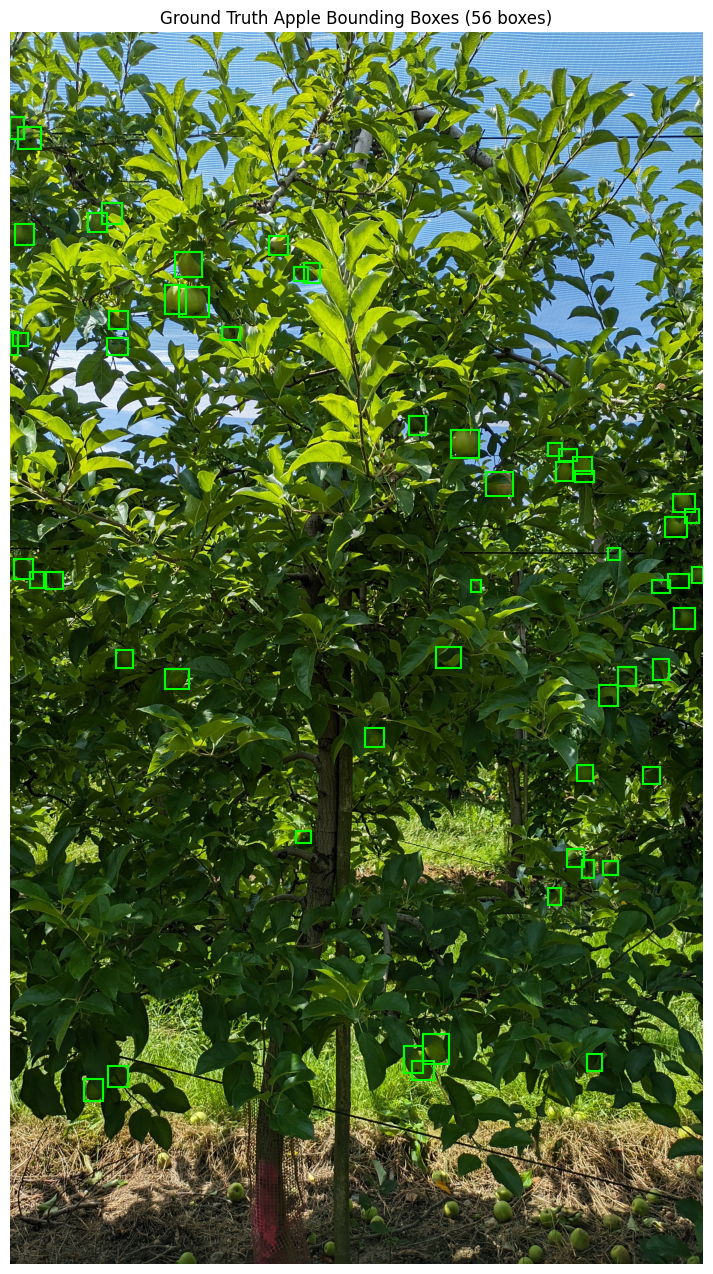

In [6]:
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(12, 16))
ax.imshow(image)

for box in apple_boxes_pixels:
    x1, y1, x2, y2 = box
    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=1.5,
        edgecolor="lime",
        facecolor="none"
    )

    ax.add_patch(rect)

ax.set_title(f"Ground Truth Apple Bounding Boxes ({len(apple_boxes_pixels)} boxes)")
ax.axis("off")
plt.show()

In [7]:
# Select 6 ground-truth boxes
selected_boxes = apple_boxes_pixels[:6].copy()

print("Selected ground-truth boxes:")
for i, box in enumerate(selected_boxes):
    print(f"Apple {i+1}: {box}")

Selected ground-truth boxes:
Apple 1: [ 24.29720709 311.23565271 101.8168678  382.97026412]
Apple 2: [  0.         276.52535687  45.12338459 351.03678488]
Apple 3: [255.69917936 591.23203916 315.86369216 653.71057168]
Apple 4: [ 17.35514792 627.09934487  77.51966071 695.36292669]
Apple 5: [300.82256396 558.83576305 366.77212606 627.09934487]
Apple 6: [540.32360526 720.81714364 628.25635473 801.11362096]


In [8]:
predicted_boxes = selected_boxes[:4].copy()

# laying down diff scenarios
# 1. if perfect prediction: no changes

# 2. if slight then we adjust by approx 10% of box width and height
predicted_boxes[1][0] += 0.1 * (selected_boxes[1][2] - selected_boxes[1][0])
predicted_boxes[1][1] += 0.1 * (selected_boxes[1][3] - selected_boxes[1][1])
predicted_boxes[1][2] += 0.1 * (selected_boxes[1][2] - selected_boxes[1][0])
predicted_boxes[1][3] += 0.1 * (selected_boxes[1][3] - selected_boxes[1][1])

# 3. if large shift then we adjust by approx 60% of box width and height
predicted_boxes[2][0] += 0.6 * (selected_boxes[2][2] - selected_boxes[2][0])
predicted_boxes[2][1] += 0.6 * (selected_boxes[2][3] - selected_boxes[2][1])
predicted_boxes[2][2] += 0.6 * (selected_boxes[2][2] - selected_boxes[2][0])
predicted_boxes[2][3] += 0.6 * (selected_boxes[2][3] - selected_boxes[2][1])

# 4. if neither then just move away the prediction to a distant coord as in the shift if too large
predicted_boxes[3] += 500

print("Simulated predictions created.")

Simulated predictions created.


In [15]:
import torch

def calculate_iou(box1, box2):
    # intersection coordinates
    x1 = torch.maximum(box1[0], box2[0])
    y1 = torch.maximum(box1[1], box2[1])
    x2 = torch.minimum(box1[2], box2[2])
    y2 = torch.minimum(box1[3], box2[3])

    # intersection dimensions
    inter_width = torch.clamp(x2 - x1, min=0)
    inter_height = torch.clamp(y2 - y1, min=0)
    intersection = inter_width * inter_height

    # box areas
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])

    # union area
    union = area1 + area2 - intersection

    iou = torch.where(
        union > 0,
        intersection / union,
        torch.zeros_like(union)
    )

    return iou

In [16]:
ground_truth = torch.tensor(selected_boxes[:4], dtype=torch.float32)
predictions = torch.tensor(predicted_boxes, dtype=torch.float32)

for i in range(len(ground_truth)):
    score = calculate_iou(
        ground_truth[i],
        predictions[i]
    )

    print(f"Apple {i+1}: IoU = {score.item():.4f}")

Apple 1: IoU = 1.0000
Apple 2: IoU = 0.6807
Apple 3: IoU = 0.0870
Apple 4: IoU = 0.0000


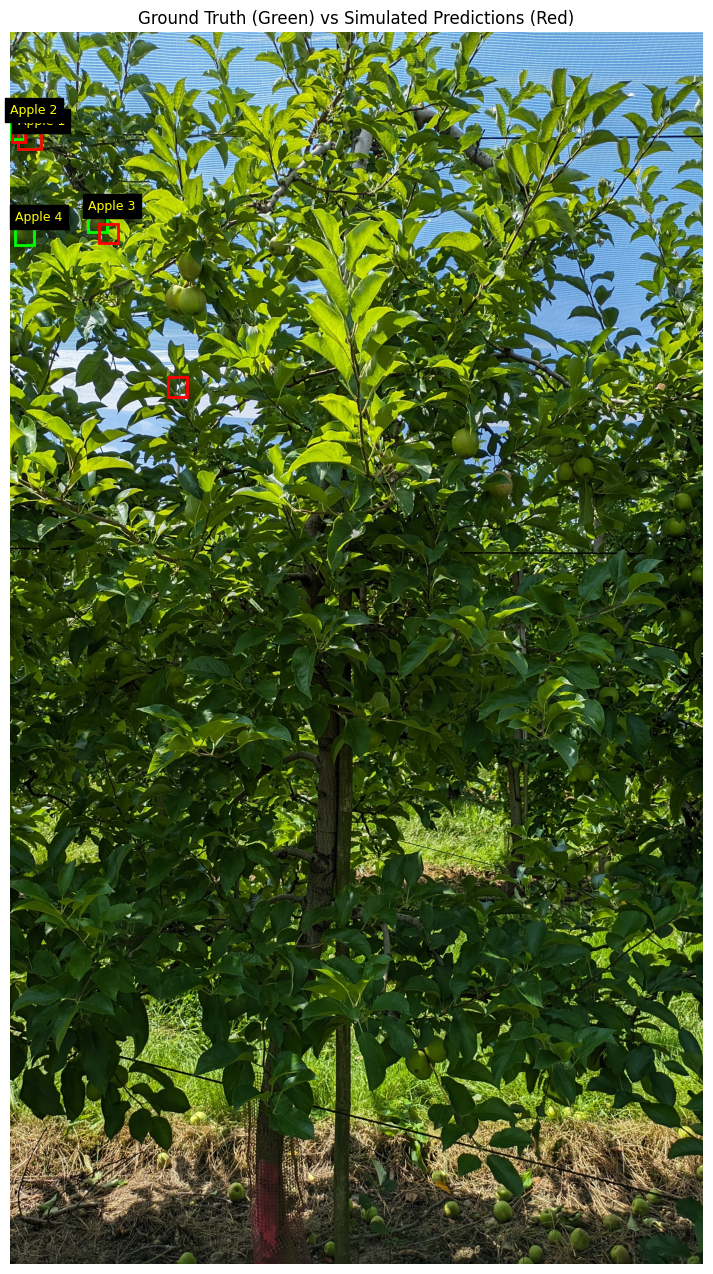

In [17]:
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(12, 16))
ax.imshow(image)

for i in range(4):
    # ground truth in lime color
    x1, y1, x2, y2 = ground_truth[i].numpy()

    gt_rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=2,
        edgecolor="lime",
        facecolor="none"
    )
    ax.add_patch(gt_rect)

    # prediction in red color
    px1, py1, px2, py2 = predictions[i].numpy()

    pred_rect = patches.Rectangle(
        (px1, py1),
        px2 - px1,
        py2 - py1,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(pred_rect)

    ax.text(x1, y1 - 10, f"Apple {i+1}",
            color="yellow", fontsize=9,
            backgroundcolor="black")

ax.set_title("Ground Truth (Green) vs Simulated Predictions (Red)")
ax.axis("off")
plt.show()

In [18]:
IOU_THRESHOLD = 0.5

for i in range(len(ground_truth)):

    score = calculate_iou(
        ground_truth[i],
        predictions[i]
    ).item()

    result = "MATCH" if score >= IOU_THRESHOLD else "NO MATCH"

    print(
        f"Apple {i+1}: IoU = {score:.4f} | {result}"
    )

Apple 1: IoU = 1.0000 | MATCH
Apple 2: IoU = 0.6807 | MATCH
Apple 3: IoU = 0.0870 | NO MATCH
Apple 4: IoU = 0.0000 | NO MATCH


In [19]:
# Pick one ground-truth box
box = selected_boxes[0].copy()

# experiment
shift_percentage = 0.3

width = box[2] - box[0]
height = box[3] - box[1]

custom_prediction = box.copy()

custom_prediction[0] += shift_percentage * width
custom_prediction[1] += shift_percentage * height
custom_prediction[2] += shift_percentage * width
custom_prediction[3] += shift_percentage * height

custom_iou = calculate_iou(
    torch.tensor(box, dtype=torch.float32),
    torch.tensor(custom_prediction, dtype=torch.float32)
)

print(f"Shift: {shift_percentage * 100:.0f}%")
print(f"IoU: {custom_iou.item():.4f}")

Shift: 30%
IoU: 0.3245
